# Tinless system optimizer

Finds the plant design with the lowest **lifetime cost** = lifetime capex (initial + cell replacements +
bare-area cleanings, all +30% soft costs) + the lifetime cost of the **energy lost**, at one electricity
price for charge and discharge. Net round-trip efficiency = (AC out − floor-cooling and heat-rejection
fans) / AC in, incl. hold losses. Capex is reported on its own; the capex–efficiency Pareto front is
read from the logs. An optional RTE floor is available. Model: `thermal/optimize.py`.

Per design: **shade-open sizing** on the clean discharge (T_max is the variable; T_min = the volume-average
block temperature at which the shades are fully open, block volume so that happens at the target duration;
deposition per cycle from the final run, none while the stick is retracted during charge and hold) →
heater cavity (smallest that charges in `charge_hr`) → tank sized on the clean stick (AC basis, energy
target enforced) → cells replaced at D = 0.1, bare areas cleaned at D = 0.01 → capex, efficiency
and cost of the energy lost with the performance averaged over every cycle of the life (clean run
averaged with a run at twice the lifetime-mean wear).

* **Physics inputs** (materials, emissivities, bandgap, liner / shade / axial-radiation switches, stick
  temperature, gaps, liner thickness, RGF pad, timesteps, heater size / max T / power) come from
  `tinless_model_input.yaml`: edit them in the YAML cell of `tinless system model.ipynb` and run it.
* **Costs, efficiencies, maintenance thresholds, ranges and fidelity** are in the inputs cell below, including
  the tank and graphite rates (`tank_costs`, `iso_graphite_per_kg`), which replace the YAML cost rates for every design.
* **Cost scenario**: `economics.cost_scenario` = `'Pilot'`, `'FOAK'` or `'NOAK'` replaces the cost and efficiency
  inputs it lists (`thermal/cost_scenarios.py`, from `docs/cost_scenarios_pilot_foak_noak.md`); the inputs cell prints
  what it replaced, the run folder gets the scenario suffix and the report marks the values it set.
* **Optimized variables and their bounds**: `DESIGN_VARS` at the top of the inputs cell.

In [1]:
import os, glob, json, time, copy
import numpy as np
import matplotlib.pyplot as plt
import importlib
import thermal.build, thermal.tank, thermal.sizing, thermal.optimize, thermal.report
for _mod in (thermal.build, thermal.tank, thermal.sizing, thermal.optimize, thermal.report):
    importlib.reload(_mod)          # pick up edits to the modules (e.g. DESIGN_VARS bounds)
from thermal import optimize as O
from thermal.build import load_config
from thermal.report import FigureStore
FIGS = FigureStore()                # figures kept for the run report (last cell)

base_cfg = load_config('tinless_model_input.yaml')
print(f"Base YAML: L {base_cfg['storage']['L']} m, block {base_cfg['storage'].get('block_height')} m, "
      f"liner {base_cfg['powerstick']['liner_side_len']} m, heater {base_cfg['heater']['side_len']} m / "
      f"{base_cfg['heater']['max_temperature']} K / {base_cfg['heater']['max_power_per_m']/1e3:.0f} kW/m (power cap; "
      f"the optimizer sizes each heater's power and cavity for charge_hr)")

Base YAML: L 3 m, block 10 m, liner 0.25 m, heater 0.15 m / 2873 K / 54 kW/m (power cap; the optimizer sizes each heater's power and cavity for charge_hr)


In [2]:
# -- Optimized variables -----------------------------------------------------------
# (name, lower, upper, integer, meaning). Change the bounds here; the names are fixed (thermal/optimize.py
# decode() turns them into the design) but can be listed in any order. Defaults: thermal.optimize.DESIGN_VARS.
DESIGN_VARS = [
    ('liner_side', 0.20, 0.60, False, 'liner side length [m]'),
    ('ps_frac',    0.0,  1.0,  False, 'powerstick side: 0.10 m + frac x (room in liner - 0.10)'),
    ('L',          3.0,  6.0,  False, 'stick length [m]'),
    ('H_frac',     0.0,  1.0,  False, 'block height: L + min_lower_zone + frac x (H_max - L - min_lower_zone)'),
    ('avg_flux',   5.0,  20.0, False, 'cell flux target [W/cm2] (continuous)'),
    ('shade_8th',  2,    48,   True,  'shade thickness i x 1/8 in (1/4 - 6 in)'),
    ('t_side',     0.5,  3.0,  False, 'tank side insulation [m]'),
    ('t_top',      0.5,  3.0,  False, 'tank top insulation [m]'),
    ('L_bot',      2.0,  4.0,  False, 'bottom stack under the hot zone (support columns + Thermax) [m]'),
    ('T_max_C',    1800.0, 2500.0, False, 'block T_max [C] (capped at geometry.T_cap_C); T_min from shade-open sizing'),
]

# -- Inputs (not optimized) ------------------------------------------------------
# Precedence: thermal.optimize.OPT_DEFAULTS < this cell < the cost scenario (if one is named).
OPT_INPUTS = {
    'P_rated': 1.0e6,            # W AC export
    'duration_hr': 50.0,          # h at P_rated: energy target, enforced on clean performance
    'charge_hr': 50.0,            # h design charge time (heater power, then cavity, sized to meet it)
    'economics': {
        'eta_out': 0.98,          # DC -> AC inverter
        'eta_in': 0.98,           # AC -> heater supply
        'cycles_per_year': 8760.0 / 168.0,   # 1-week cycle: 50 h charge + hold + 50 h discharge
        'lifetime_yr': 30.0,
        'soft_cost_frac': 0.30,   # tax, freight, soft costs on all capex (incl. replacements)
        'elec_price': 87.0,       # $/MWh, same for charge and discharge: prices the energy lost
        # cost scenario from docs/cost_scenarios_pilot_foak_noak.md: 'Pilot' | 'FOAK' | 'NOAK' replaces the
        # cost / efficiency inputs it lists (thermal/cost_scenarios.py; printed below); None = this cell as written
        'cost_scenario': 'Pilot',
    },
    'objective': {'rte_min': 0.0},    # optional floor on net RTE (0 = none)
    'costs': {
        'cell_per_cm2': 2.0,      # $/cm2 cell-covered powerstick face (also each replacement)
        'stick_per_m': 100.0,     # $/m stick length
        'stick_fixed': 5000.0,    # $/stick
        'iso_graphite_per_kg': 10.0,       # $/kg iso-molded graphite: tank support columns + heaters (None = YAML)
        # heater, per heater: heater_fixed + element graphite (A_cross x (H_block + t_top) x heater.density) x
        # heater_graphite_per_kg. Scenario heater_fixed: Pilot 7,500 / FOAK 6,000 / NOAK 4,500 $
        'heater_fixed': 0.0,               # $/heater
        'heater_graphite_per_kg': None,    # $/kg heater graphite; None = iso_graphite_per_kg
        'charge_electrics_per_kW': 75.0,   # $/kW heater supply
        'inverter_per_kW': 100.0,          # $/kW_AC, sized on peak plant output (>= P_rated)
        'heat_rejection_per_kWth': 250.0,  # $/kW_th dry cooler, sized on peak stick heat rejection
        'bare_clean_per_stick': 10000.0,       # $/stick per bare-area cleaning (count is tracked)
        'interconnect_per_kW': 150.0,      # $/kW grid connection, sized on max(peak charge, peak output) AC
                                           #   (LBNL: completed storage projects avg ~$151/kW) PLACEHOLDER
        # liner: grafoil walls (4 x side x L) + CFC floor (side^2 x floor_area_factor, extra for upper features)
        'liner_wall_per_m2': 55.0,         # $/m2 grafoil
        'liner_floor_per_m2': 1000.0,      # $/m2 CFC
        'liner_floor_area_factor': 2.0,
        # shades: 8 RGF vanes per stick over the full block height, an axle per vane up through the top
        # insulation (t_top + shade_axle_extra) to the drive
        'shade_rgf_per_m3': 15000.0,       # $/m3 rigid graphite felt, machined (PLACEHOLDER)
        'shade_axle_per_m': 300.0,         # $/m graphite / CFC axle (PLACEHOLDER)
        'shade_axle_extra': 0.5,           # m axle above the top insulation
        'shade_drive': 'linkage',          # 'linkage': 1 motor + linkage per stick | 'per_vane': 1 motor per vane
        'shade_motor': 1500.0,             # $/motor incl. driver (PLACEHOLDER)
        'shade_linkage': 2000.0,           # $/stick linkage, 'linkage' drive (PLACEHOLDER)
    },
    # tank and graphite rates for every design, replacing the YAML tank.costs central values (the YAML's
    # low / high only matter for the single-design tank report). Physics stays in the YAML.
    'tank_costs': {
        'storage_graphite_per_kg': 1.0,   # $/kg storage block graphite (pass-through line)
        'steel_per_t': 7500.0,            # $/t tank shell, bottom, roof, field-erected
        'deck_per_t': 6000.0,             # $/t deck trusses
        'structural_steel_per_kg': 5.0,   # $/kg bearing plates, fabricated
        'thermax_per_kg': 2.5,            # $/kg Thermax (side, top, bottom)
        'oxide_per_kg': 2.0,              # $/kg oxide posts under the graphite columns
        'gas_tight_fixed': 300000.0,      # $ gas tightness, nozzles, gas holder
        'per_penetration': 1500.0,        # $ per stick + heater roof penetration
        'tie_grid': 1500.0,               # $ per column
        'floor_per_m2': 935.0,            # $/m2 floor plate upgrade, fins, welds
        'slab_per_m2': 470.0,             # $/m2 HT concrete slab, rails, firebrick caps
        'cellular_glass_per_m2': 165.0,   # $/m2
        'mat_per_m3': 1300.0,             # $/m3 structural mat
        'fans_per_m3s': 10000.0,          # $ per m3/s floor-cooling fans, louvres, exhaust, controls
    },
    'parasitics': {'heat_rejection_kWe_per_kWth': 0.03},   # dry-cooler fans + pumps; floor fans from the tank model
    'deposition': {
        'd_dead_nm': 10.0,        # linear: cells dead and bare / inactive emissivity at emis_end at 10 nm
        'emis_end': 0.8,
        'cell_replace_D': 0.1,    # replace cells at this degradation
        'bare_clean_D': 0.01,     # clean bare areas at this degradation
    },
    'geometry': {
        'ps_liner_gap': 0.02,     # m min powerstick -> liner clearance per side
        'heater_min_gap': 0.25,   # m min heater -> cavity wall clearance
        'H_max': 14.0,            # m block height upper bound (the 30 m tank-height limit cuts tall combinations)
        'min_lower_zone': 0.25,   # m block always this much taller than the stick (floor, liner bottom, pad)
        'T_cap_C': 2500.0,        # C max block temperature (heater max 2600 C in the YAML)
        'T_min_floor_C': 1400.0,  # C lowest allowed T_min (T_min comes from the shade-open sizing)
        'min_wall': 0.30,         # m min graphite wall between neighbouring cavities (stick cavities at 45 deg)
        'swing_min': 200.0, 'swing_max': 1000.0,   # C allowed swing
    },
    # shade-open sizing: shades must open within tol_T [K] of T_min and tol_t of the duration
    'sizing': {'tol_T': 3.0, 'tol_t': 0.01, 'max_iter': 6, 'swing_guess': 500.0},
    'limits': {'D_tank_max': 80.0, 'H_tank_max': 30.0},
    'fidelity': {'dz': 0.5, 'nrad': 5, 'dt_scale': 2.0, 'vane_rays': 2 ** 12, 'heater_ar_tol': 0.03},
    'design_vars': DESIGN_VARS,
}
opt = O.build_opt(OPT_INPUTS)       # defaults < this cell < cost scenario

_sc = O.scenario_name(opt)
if _sc:
    from thermal.cost_scenarios import NOTES
    _flat_in = O._flat(OPT_INPUTS)
    print(f"Cost scenario {_sc.upper()}: {NOTES[_sc]}\nChanges (this cell -> scenario):")
    for _k, _s in opt['_sources'].items():
        _v = O._flat(opt).get(_k)
        if _s.startswith('scenario') and _flat_in.get(_k, '(default)') != _v:
            print(f"  {_k:42s} {_flat_in.get(_k, '(default)')!s:>12} -> {_v}")
else:
    print('Cost scenario: none (this cell as written)')
print('\nOptimized variables:')
for name, lo, hi, integer, desc in O.design_vars(opt):
    print(f"  {name:11s} [{lo:g}, {hi:g}]{' int' if integer else '    '}  {desc}")

Cost scenario PILOT: Pilot (2027): eta_in / eta_out 0.95; cells $36.5/cm2 all-in module cost (cells push the optimum toward high flux: consider raising the avg_flux bound).
Changes (this cell -> scenario):
  economics.eta_out                                  0.98 -> 0.95
  economics.eta_in                                   0.98 -> 0.95
  economics.soft_cost_frac                            0.3 -> 0.55
  costs.cell_per_cm2                                  2.0 -> 36.52
  costs.stick_per_m                                 100.0 -> 339.0
  costs.stick_fixed                                5000.0 -> 7510.0
  costs.iso_graphite_per_kg                          10.0 -> 20.0
  costs.heater_fixed                                  0.0 -> 7500.0
  costs.charge_electrics_per_kW                      75.0 -> 0.0
  costs.inverter_per_kW                             100.0 -> 0.0
  costs.heat_rejection_per_kWth                     250.0 -> 780.0
  costs.interconnect_per_kW                         150.0 -> 35

In [ ]:
# -- Heater leads in the system optimizer ------------------------------------------------
# Every design gets the cost and losses of its heater current leads (graphite / tungsten / water-cooled
# copper through the top insulation, graphite joint opened when idle) from a lead table: optimal leads on
# t_top x block T_max at two currents, built with the cost weights above and LEAD_INPUTS below, and
# interpolated at each design's heater current (P_heater / heater.voltage). Per design this adds:
#   capex     a 'heater leads' line (lead material + joints) and lead Joule power on the heater supply,
#             interconnect and the heat-rejection capacity (cooled copper)
#   energy    lead Joule heat while charging (bought) + heat the leads drain from the storage (put back by
#             the heaters) + heat-rejection fans on the heat the copper rejects
# and the element graphite then covers the block height only (the leads replace the length through the
# roof insulation). Built here every session with this session's inputs (~11 min on 20 workers; also
# saved in opt_runs/_lead_tables); the run cell checks it still matches the inputs and copies it into the
# run folder. LEAD_INPUTS also drives the separate lead optimizer at the end of the notebook.
# Model: thermal/heater_leads.py.
import thermal.heater, thermal.heater_leads
importlib.reload(thermal.heater); importlib.reload(thermal.heater_leads)
from thermal import heater_leads as HL

USE_LEAD_TABLE = True      # False: leads not modelled (element through the roof insulation, as before)
REBUILD_LEAD_TABLE = True  # True: build a new table every session; False: reuse a saved table built with
                           #   exactly these inputs (costs, scenario, lead inputs, grid), else build

# zone sets to optimize (hot -> cold), each run with the last zone passive and water-cooled; zones an
# optimum leaves at min_zone_len are then tried removed. Materials: HL.MATERIALS ('graphite', 'tungsten',
# 'molybdenum', 'copper', 'aluminum', 'stainless'); water-cooled last zone: copper, aluminum, stainless
LEAD_ZONE_SETS = {
    'copper':    ['graphite', 'tungsten', 'copper'],
    'stainless': ['graphite', 'tungsten', 'stainless'],
}

LEAD_INPUTS = {
    'zones': LEAD_ZONE_SETS['copper'],             # default set (HL.optimize_leads without zones=)
    'n_leads': 2,                  # per heater (supply + return)
    'design': None,                # None = LEAD_YAML; or a design row from the results cell, e.g. best[0]
                                   #   (its t_top, T_min, T_max, block height, heater power, number of heaters)
    'P_heater': None,              # W heater power override; None -> the design (YAML: max_power_per_m x H)
    'voltage': None,               # V override of heater.voltage (current = P / V)
    # materials: max service temperature T_max [K], $/m3 (PLACEHOLDERS), lead-surface emissivity.
    # graphite $/m3 None -> heater graphite $/kg (costs above) x 1850 kg/m3
    'materials': {
        'graphite': {'T_max': 3000 + 273.15, 'cost_per_m3': None, 'emissivity': 0.85},
        'tungsten': {'T_max': 2500 + 273.15, 'cost_per_m3': 2.5e6, 'emissivity': 0.25},   # ~$130/kg bar
        'copper':   {'T_max': 200 + 273.15, 'cost_per_m3': 1.1e5, 'emissivity': 0.10},    # ~$12/kg bar
        'molybdenum': {'T_max': 1800 + 273.15, 'cost_per_m3': 6.0e5},                      # ~$60/kg bar
        'aluminum': {'T_max': 150 + 273.15, 'cost_per_m3': 1.4e4},                         # ~$5/kg bar
        'stainless': {'T_max': 800 + 273.15, 'cost_per_m3': 5.0e4, 'emissivity': 0.35},   # 304, ~$6/kg bar
    },
    'joint_cost': 0.0,             # $ per joint between zones (PLACEHOLDER)
    # every zone >= min_zone_len; a zone an optimum leaves at the minimum is tried removed
    # (graphite -> copper, tungsten -> copper, graphite only, ...). Joints: T <= the colder material's T_max
    'min_zone_len': 0.05,          # m
    # idle disconnect (set per case by LEAD_COMPARE_BREAK; None here = connected): open gap and mechanism cost
    'idle_break_after': None,
    'break_gap': 0.01,             # m open gap: radiation + argon conduction across it
    'break_cost': 0.0,             # $ per lead, disconnect mechanism (PLACEHOLDER)
    # temperatures [K]; None -> from the design
    'T_hot_charge': None,          # lead hot end while charging (None: heater.max_temperature)
    'T_ins_hot': None,             # Thermax hot (bottom) face, charge and idle (None: block T_max)
    'T_idle': None,                # lead hot end, no current (None: block mean)
    'T_ins_cold': 80 + 273.15,     # Thermax top face
    'T_term': 40 + 273.15,         # water-cooled terminal clamp at the top face (passive last zone)
    'T_cool': 40 + 273.15,         # water-cooled last zone
    # exchange with the insulation (undisturbed Thermax: exact 1-D profile with its k(T), hot face -> top face)
    'gap': 0.005,                  # m radial gap lead -> bore (argon)
    'r_far': 0.5,                  # m radius where the Thermax is undisturbed; None -> bore wall undisturbed
    'eps_wall': 0.9,               # bore wall emissivity
    'd_bounds': (0.02, 0.50),      # m bar diameter bounds per zone
    'de': {'popsize': 12, 'maxiter': 150, 'tol': 1e-7, 'seed': 0},
}


# lead table grid (system design variable ranges) and lead type
LEAD_TABLE = {
    't_top': [0.5, 1.0, 1.5, 2.0, 2.5, 3.0],        # m (system design variable bounds)
    'T_max_C': [1800.0, 2033.3, 2266.7, 2500.0],    # C block T_max (design variable bounds)
    'I_kA': [4.0, 10.0],                            # heater current = P_heater / voltage
    'idle_break_after': 'graphite',                 # option 2: graphite joint open when idle
}

if USE_LEAD_TABLE:
    lead_table = HL.build_lead_table(base_cfg, OPT_INPUTS, LEAD_INPUTS, LEAD_TABLE, force=REBUILD_LEAD_TABLE)
    opt = O.merge(opt, {'leads': {'table': lead_table.path, 'n_per_heater': LEAD_INPUTS['n_leads']}})
    print(lead_table.summary())
else:
    opt = O.merge(opt, {'leads': {'table': None}})
    print("Heater leads not modelled (USE_LEAD_TABLE = False)")


In [3]:
# -- Baseline: the design currently in the YAML -----------------------------------
baseline = O.design_from_cfg(base_cfg)
_t0 = time.perf_counter()
res_base = O.evaluate(baseline, base_cfg, opt)
print(f"({time.perf_counter() - _t0:.0f} s)")
print(O.summary(res_base))

(114 s)
Design: liner 250 mm, powerstick 130 mm, L 3.00 m, block H 10.00 m, flux 10.0 W/cm2, shade 1.54 in, insulation side 1.00 / top 1.50 m, bottom stack 2.00 m, T_max 2100 C
Plant: 19 sticks + heaters, hot zone 12.7 m, tank 14.8 x 20.0 m; block r 0.661-1.237 m, T 1837-2100 C (shade-open sizing: volume x1.064, 4 runs); heater 151 kW, cavity 634 mm (area_ratio 4.72); element tube OD 134 mm x 13.4 mm wall, 23.84 mOhm, 2.5 kA at 60 V, 109 kg
Grid: pitch 1.601 m, graphite walls stick-heater 550, stick-stick 1226, heater-heater 1630 mm (stick cavities at 45 deg)
Floor (design-day air 10 m/s): max 49 C, column hot spot 131 C; foundation 133 kPa
Cycle: charge 49.6 h, hold 69.2 h, discharge 50.5 h clean / 48.0 h at 2x life-mean wear; energy vs target +6.4% (clean); losses 4.21 %/day
Per stick: 3,161 kWh clean, 2,944 kWh life average (2,727 kWh at D_cell 0.083 / D_bare 0.010 = 2x life-mean wear); deposition 0.91 pm/cycle
Maintenance: 1 cell replacements (every 21.2 yr), 13 bare-area cleanings

In [ ]:
# -- Differential evolution ------------------------------------------------------
# ~1-2 min per design on one core (shade-open sizing: ~3-4 discharges); WORKERS designs in
# parallel. Each generation = POPSIZE x 10 designs. Every evaluation is logged to LOG_DIR (load it below while a run is going).
# The capex-efficiency Pareto plot below pools every run under opt_runs/.
RUN_DE   = True
WORKERS  = 20
POPSIZE  = 10             # x 10 variables = 100 designs / generation
MAXITER  = 25
SEED     = 0
LOG_DIR  = os.path.join('opt_runs', time.strftime('%Y%m%d_%H%M%S') + f"_p{opt['economics']['elec_price']:.0f}"
                       + (f"_{O.scenario_name(opt)}" if O.scenario_name(opt) else ''))   # e.g. _p87_noak
RELOAD_RUN = None                                  # e.g. 'opt_runs/20261119_164422_p75': skip the run, reload that folder's log
                          #   (results, plots and the report below then use it)
if RELOAD_RUN:
    RUN_DE, LOG_DIR = False, RELOAD_RUN

if RUN_DE and USE_LEAD_TABLE:
    # heater lead table: must match this session's inputs (rebuilt if OPT_INPUTS / LEAD_INPUTS / LEAD_TABLE
    # changed since the opt_leads cell); a copy goes into the run folder and the run uses that copy
    if lead_table.data['key'] != HL.table_key(base_cfg, OPT_INPUTS, LEAD_INPUTS, LEAD_TABLE):
        print("lead table out of date with the inputs: rebuilding")
        lead_table = HL.build_lead_table(base_cfg, OPT_INPUTS, LEAD_INPUTS, LEAD_TABLE, force=True)
    os.makedirs(LOG_DIR, exist_ok=True)
    _lt_path = os.path.join(LOG_DIR, 'lead_table.json')
    with open(_lt_path, 'w') as _fh:
        json.dump(lead_table.data, _fh, indent=1, default=float)
    opt = O.merge(opt, {'leads': {'table': _lt_path, 'n_per_heater': LEAD_INPUTS['n_leads']}})
    print(f"heater leads: table {lead_table.data['key']} -> {_lt_path}")

if RUN_DE:
    _t0 = time.perf_counter()
    _gen = [0]

    def _cb(xk, convergence):          # once per generation: best feasible design so far (from the log)
        _gen[0] += 1
        rows = O.load_log(LOG_DIR)
        feas = [r for r in rows if r.get('feasible')]
        if feas:
            b = min(feas, key=lambda r: r['lifetime_cost'])
            best_txt = (f"${b['lifetime_cost']/1e6:,.1f}M (capex ${b['capex_total']/1e6:,.1f}M, "
                        f"RTE {b['RTE']*100:.1f}%)")
        else:
            best_txt = 'none feasible yet'
        print(f"gen {_gen[0]:3d}  {(time.perf_counter() - _t0)/60:6.1f} min  {len(rows)} designs  "
              f"best {best_txt}  convergence {convergence:.3f}", flush=True)

    x0 = O.encode(baseline, opt)
    de = O.run_de(base_cfg, opt, LOG_DIR, maxiter=MAXITER, popsize=POPSIZE, workers=WORKERS, seed=SEED,
                  x0=x0, callback=_cb)
    print(f"done in {(time.perf_counter() - _t0)/60:.1f} min, {de.nfev} designs; best f {de.fun:.2f}")
    with open(os.path.join(LOG_DIR, 'inputs.json'), 'w') as fh:
        json.dump(dict(opt=opt, base_yaml='tinless_model_input.yaml', de=dict(fun=de.fun, x=list(de.x))), fh,
                  indent=1, default=str)

gen   1    26.2 min  256 designs  best $45.2M (capex $29.6M, RTE 28.0%)  convergence 0.000
gen   2    37.8 min  384 designs  best $44.5M (capex $29.8M, RTE 28.3%)  convergence 0.000
gen   3    49.3 min  512 designs  best $44.4M (capex $28.1M, RTE 26.7%)  convergence 0.000
gen   4    64.5 min  640 designs  best $44.4M (capex $28.1M, RTE 26.7%)  convergence 0.000
gen   5    80.0 min  768 designs  best $43.6M (capex $28.0M, RTE 26.8%)  convergence 0.000
gen   6    91.6 min  896 designs  best $43.6M (capex $28.0M, RTE 26.8%)  convergence 0.000
gen   7   108.2 min  1024 designs  best $43.3M (capex $27.9M, RTE 27.4%)  convergence 0.000


3328 designs evaluated, 2137 feasible, 99 failed

#1  (f 540.69)
Design: liner 315 mm, powerstick 204 mm, L 9.45 m, block H 10.86 m, flux 8.0 W/cm2, shade 3.38 in, insulation side 2.19 / top 1.78 m, bottom stack 3.33 m, T_max 2356 C
Plant: 107 sticks + heaters, hot zone 34.7 m, tank 39.2 x 29.2 m; block r 0.826-1.544 m, T 1772-2356 C (shade-open sizing: volume x1.006, 4 runs); heater 585 kW, cavity 691 mm (area_ratio 3.62)
Grid: pitch 1.983 m, graphite walls stick-heater 720, stick-stick 1507, heater-heater 2114 mm (stick cavities at 45 deg)
Floor (design-day air 10 m/s): max 53 C, column hot spot 104 C; foundation 159 kPa
Cycle: charge 49.6 h, hold 68.7 h, discharge 50.5 h clean / 49.0 h at 2x life-mean wear; energy vs target +1.1% (clean); losses 0.67 %/day
Per stick: 12,105 kWh clean, 11,760 kWh life average (11,414 kWh at D_cell 0.026 / D_bare 0.009 = 2x life-mean wear); deposition 0.17 pm/cycle
Maintenance: 0 cell replacements (every 113.3 yr), 2 bare-area cleanings besides (every

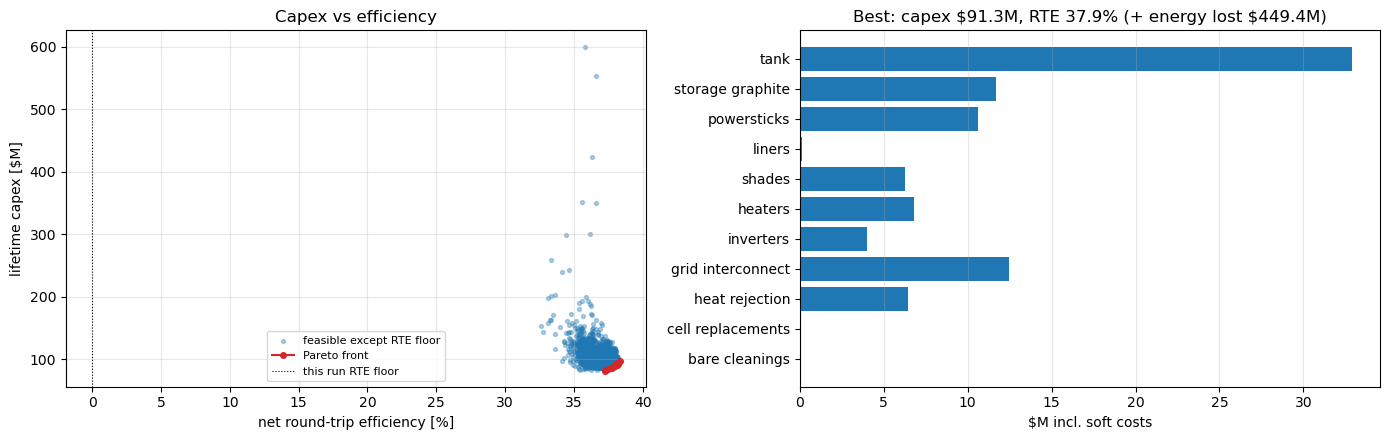

In [ ]:
# -- Results: best designs in a run, and the capex-efficiency front ---------------
# Point LOG_DIR at any run folder under opt_runs/ to reload it.
rows = O.load_log(LOG_DIR)
ok = [r for r in rows if r.get('feasible')]
print(f"{len(rows)} designs evaluated, {len(ok)} feasible, {sum('error' in r for r in rows)} failed")
best = sorted(ok, key=lambda r: r['lifetime_cost'])[:10]
for i, r in enumerate(best):
    print(f"\n#{i+1}  (f {r['f']:.2f})")
    print(O.summary(r))

# Pareto front (designs whose only violation is the RTE floor count). Add other run folders
# to PARETO_DIRS only if they used the same model and inputs.
PARETO_DIRS = [LOG_DIR]
all_rows = [r for d in PARETO_DIRS for r in O.load_log(d)]
pool = [r for r in all_rows if 'capex_total' in r and set(r.get('violations') or {}) <= {'rte'}]
front = O.pareto(all_rows)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
if pool:
    ax[0].scatter([r['RTE'] * 100 for r in pool], [r['capex_total'] / 1e6 for r in pool], s=8, alpha=.35,
                  label='feasible except RTE floor')
    ax[0].plot([r['RTE'] * 100 for r in front], [r['capex_total'] / 1e6 for r in front], 'o-', c='C3', ms=4,
               label='Pareto front')
    ax[0].axvline(opt['objective']['rte_min'] * 100, c='k', ls=':', lw=.8, label='this run RTE floor')
ax[0].set_xlabel('net round-trip efficiency [%]'); ax[0].set_ylabel('lifetime capex [$M]')
ax[0].grid(alpha=.3); ax[0].legend(fontsize=8); ax[0].set_title('Capex vs efficiency')
if best:
    b = best[0]
    parts = {k.split(' (')[0]: v * (1 + opt['economics']['soft_cost_frac']) for k, v in b['capex_lines'].items()}
    parts['cell replacements'] = b['n_rep'] * b['rep_cost']
    parts['bare cleanings'] = b['n_clean'] * b['clean_cost']
    ax[1].barh(list(parts), np.array(list(parts.values())) / 1e6)
    ax[1].set_xlabel('$M incl. soft costs'); ax[1].invert_yaxis(); ax[1].grid(alpha=.3, axis='x')
    ax[1].set_title(f"Best: capex \\${b['capex_total']/1e6:,.1f}M, RTE {b['RTE']*100:.1f}% "
                    f"(+ energy lost \\${b['loss_cost']/1e6:,.1f}M)")
plt.tight_layout()
FIGS.keep('pareto_and_capex', 'Left: lifetime capex vs net round-trip efficiency of every feasible design, with the Pareto front. Right: capex breakdown of the optimum (incl. soft costs).')
plt.show()

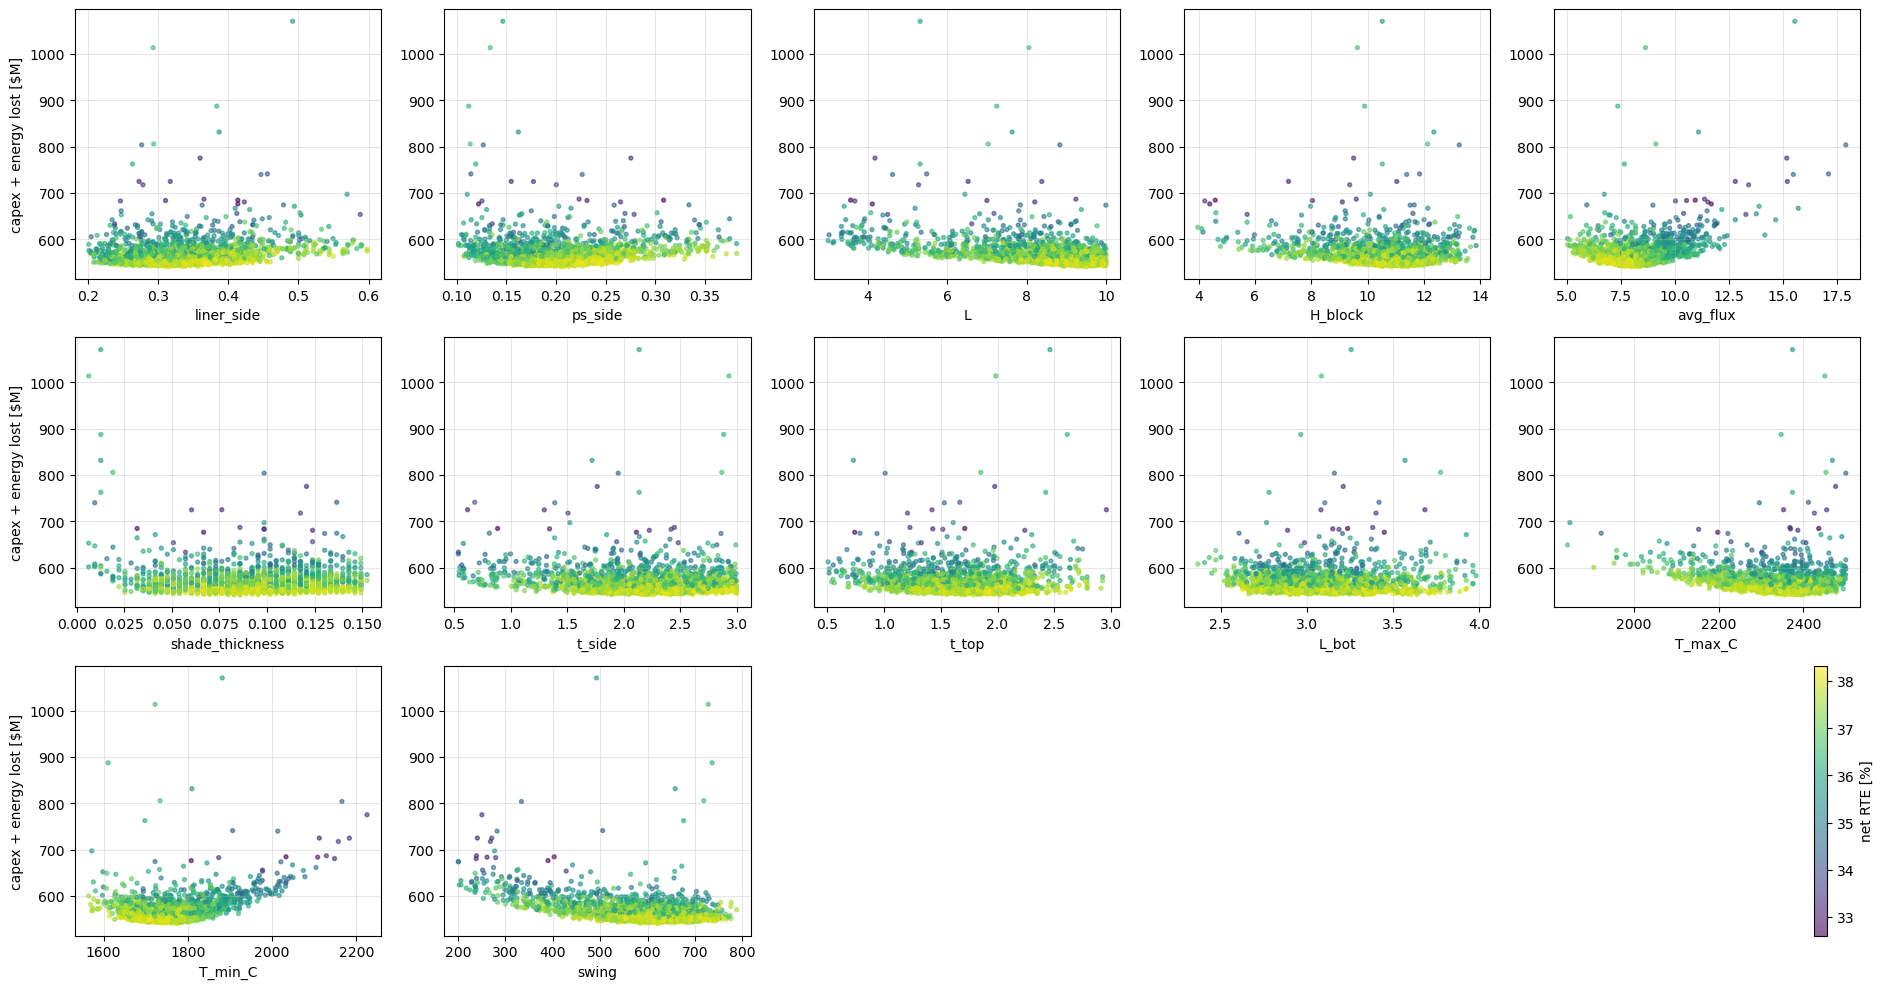

In [ ]:
# -- Variable scatter: each optimized variable vs objective (capex + energy lost; colour = RTE) --
if ok:
    keys = ['liner_side', 'ps_side', 'L', 'H_block', 'avg_flux', 'shade_thickness', 't_side', 't_top',
            'L_bot', 'T_max_C', 'T_min_C', 'swing']           # last two: sizing outputs
    fig, axs = plt.subplots(3, 5, figsize=(19, 10))
    v = np.array([r['lifetime_cost'] for r in ok]) / 1e6
    e = np.array([r['RTE'] for r in ok]) * 100
    for ax, k in zip(axs.flat, keys):
        sc = ax.scatter([r['design'].get(k, r.get(k)) for r in ok], v, c=e, s=8, alpha=.6, cmap='viridis')
        ax.set_xlabel(k); ax.grid(alpha=.3)
    for ax in axs.flat[len(keys):]:
        ax.axis('off')
    fig.colorbar(sc, ax=axs.flat[-1], label='net RTE [%]')
    for ax in axs[:, 0]:
        ax.set_ylabel('capex + energy lost [$M]')
    plt.tight_layout()
    FIGS.keep('variable_scatter', 'Objective (lifetime capex + energy lost) of every feasible design vs each optimized variable and the sizing outputs T_min and swing; colour = net RTE. A tight lower edge means the variable matters; a flat one means it does not.')
    plt.show()

c:\Users\NateColgan\Documents\thermal modelling\thermal\build.py:335: UserWarning: vane angle estimate: R''=0.119 m2K/W or H/L=1.15 outside the vane table; nearest data used
  sim.axial_model = VaneHybridRadiation(
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:523: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:652: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))


[discharge] T_avg=2039 K reached cutoff 2045 K at t=50.5000 hr (181800.0 s) — powerstick removed, conduction-only phase begins.


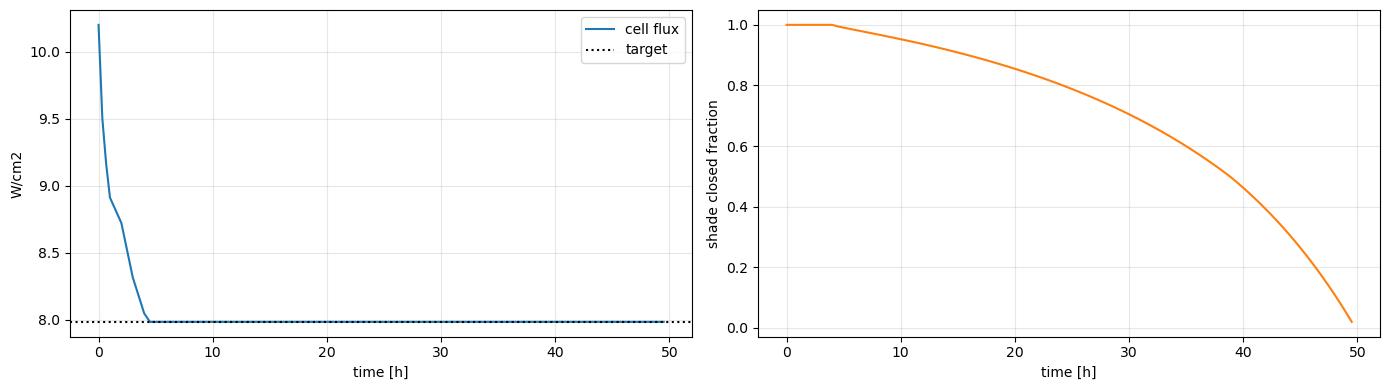

{'Q_rej_peak': 353672.509, 'E_rej': 53850961658.263, 'P_elec_peak': 291869.419, 't_on_hr': 49.5, 'flux_target': 7.985, 'E_rad': 97430464565.084, 'E_sink': 917153672.102, 'E_released': 98347618237.185, 'E_cell': 94626660825.797, 'E_el': 43579502906.821, 'frac_above': 0.081, 'frac_band': 0.919, 'frac_below': 0.0, 'E_frac_above': 0.087, 'E_frac_below': 0.0, 'flux_mean': 8.032, 'flux_std': 0.204, 'flux_rms_dev': 0.21, 'flux_max': 9.503, 'flux_end': 7.985, 'P_elec_end': 243049.598}


In [ ]:
# -- Cell-flux band of a design: time above / at / below the target (clean cells) ---------
# Re-runs the clean discharge of the best feasible design (or the baseline).
_r = best[0] if best else res_base
_cfg = O.design_cfg(base_cfg, _r['design'], opt)
_cfg['heater']['area_ratio'] = _r.get('heater_area_ratio', _cfg['heater'].get('area_ratio'))
if 'T_min_C' in _r:                                   # the sized block
    _cfg['storage']['T_min'] = _r['T_min_C'] + 273.15
    _cfg['storage']['block_temp_range'] = _r['swing']
    _cfg['storage']['volume_factor'] = _r['volume_factor']
_m, _run, _st, _fm = O._discharge(_cfg, opt, deposition=False)
_ps = _m.powerstick
_A = 4 * _ps.width * _ps.height * (1 - _ps.f_bare) * _ps.f_active * 1e4
_t = _run['time'] / 3600
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(_t, _run['Q_cell'] / _A, label='cell flux')
ax[0].axhline(_m.avg_flux, c='k', ls=':', label='target')
ax[0].set_xlabel('time [h]'); ax[0].set_ylabel('W/cm2'); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot(_t, _run['f_shade'], c='C1'); ax[1].set_xlabel('time [h]'); ax[1].set_ylabel('shade closed fraction')
ax[1].grid(alpha=.3)
plt.tight_layout()
FIGS.keep('flux_band', 'Clean discharge of the optimum (screening settings): cell flux vs the target, and the shade closed fraction (1 = closed, 0 = fully open). The shades open fully at the end of the discharge by construction (shade-open sizing).')
plt.show()
print({k: round(v, 3) for k, v in _fm.items() if isinstance(v, float)})

In [ ]:
# -- Verify the top designs at detailed settings (0.33 m rings, 2^14 rays, full timestep) --
N_VERIFY = 3
verified = []                         # (screening row, detailed result) for the report
for i, r in enumerate(best[:N_VERIFY]):
    _t0 = time.perf_counter()
    rv = O.evaluate(r['design'], base_cfg, opt, fidelity=O.DETAILED)
    verified.append((r, rv))
    print(f"\n#{i+1} detailed ({time.perf_counter() - _t0:.0f} s): objective ${rv.get('lifetime_cost', np.nan)/1e6:,.1f}M "
          f"vs screening ${r['lifetime_cost']/1e6:,.1f}M; RTE {rv.get('RTE', np.nan)*100:.1f}% vs {r['RTE']*100:.1f}%; "
          f"feasible {rv.get('feasible')} {rv.get('violations')}")
    print(O.summary(rv))


#1 detailed (247 s): objective $544.2M vs screening $540.7M; RTE 37.9% vs 37.9%; feasible True {}
Design: liner 315 mm, powerstick 204 mm, L 9.45 m, block H 10.86 m, flux 8.0 W/cm2, shade 3.38 in, insulation side 2.19 / top 1.78 m, bottom stack 3.33 m, T_max 2356 C
Plant: 107 sticks + heaters, hot zone 34.9 m, tank 39.4 x 29.2 m; block r 0.826-1.553 m, T 1778-2356 C (shade-open sizing: volume x1.010, 4 runs); heater 587 kW, cavity 691 mm (area_ratio 3.62)
Grid: pitch 1.994 m, graphite walls stick-heater 731, stick-stick 1522, heater-heater 2129 mm (stick cavities at 45 deg)
Floor (design-day air 10 m/s): max 53 C, column hot spot 104 C; foundation 160 kPa
Cycle: charge 49.8 h, hold 68.6 h, discharge 50.2 h clean / 49.0 h at 2x life-mean wear; energy vs target +1.4% (clean); losses 0.68 %/day
Per stick: 12,151 kWh clean, 11,838 kWh life average (11,525 kWh at D_cell 0.026 / D_bare 0.009 = 2x life-mean wear); deposition 0.17 pm/cycle
Maintenance: 0 cell replacements (every 115.4 yr), 2 

block: shade-open sizing (T_min and volume, T_max fixed) ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\build.py:335: UserWarning: vane angle estimate: R''=0.119 m2K/W or H/L=1.15 outside the vane table; nearest data used
  sim.axial_model = VaneHybridRadiation(
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:523: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:550: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:652: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:667: RuntimeWarning: Mean of empty slice
  np.nanmean(_st['T_foil_inner']))


[discharge] T_avg=2040 K reached cutoff 2045 K at t=49.9167 hr (179700.0 s) — powerstick removed, conduction-only phase begins.


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:651: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:653: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:654: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))


pass 1: T_min 2044.8 K, volume x1.0000 (r_out 1.5411 m) -> shades open at 2046.2 K (+1.4), 49.42 h (-1.17%)


c:\Users\NateColgan\Documents\thermal modelling\thermal\build.py:335: UserWarning: vane angle estimate: R''=0.119 m2K/W or H/L=1.15 outside the vane table; nearest data used
  sim.axial_model = VaneHybridRadiation(
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:523: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:550: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:652: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:667: RuntimeWarning: Mean of empty slice
  np.nanmean(_st['T_foil_inner']))


[discharge] T_avg=2041 K reached cutoff 2046 K at t=50.4167 hr (181500.0 s) — powerstick removed, conduction-only phase begins.


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:651: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:653: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:654: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))


pass 2: T_min 2046.2 K, volume x1.0094 (r_out 1.5475 m) -> shades open at 2047.1 K (+0.9), 49.92 h (-0.17%)
charge ...
heater: power + cavity search ...
Block fully charged: T_avg=2629.9 K >= 2629.3267232309126 K at t=36.17 hr
Block fully charged: T_avg=2629.4 K >= 2629.3267232309126 K at t=39.00 hr
Block fully charged: T_avg=2629.6 K >= 2629.3267232309126 K at t=43.67 hr
Block fully charged: T_avg=2630.3 K >= 2629.3267232309126 K at t=47.50 hr
Block fully charged: T_avg=2630.5 K >= 2629.3267232309126 K at t=49.83 hr
Block fully charged: T_avg=2629.7 K >= 2629.3267232309126 K at t=51.00 hr
Block fully charged: T_avg=2629.5 K >= 2629.3267232309126 K at t=50.33 hr
Block fully charged: T_avg=2629.4 K >= 2629.3267232309126 K at t=50.00 hr
Block fully charged: T_avg=2629.4 K >= 2629.3267232309126 K at t=50.00 hr
heater sized: 582 kW, cavity Ø691 mm (area_ratio 3.62), charge 50.0 h
tank ...
Design as run: block r 0.826-1.548 m x 10.86 m (volume_factor 1.0094, shade-open sized); heater 582 kW

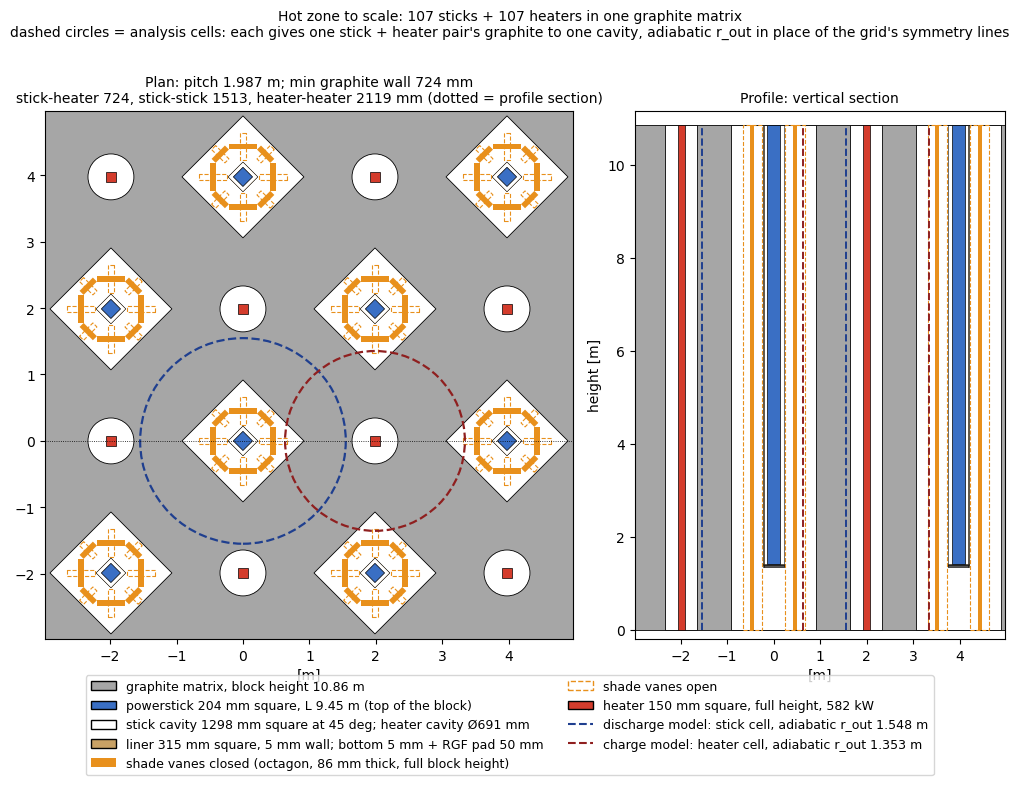

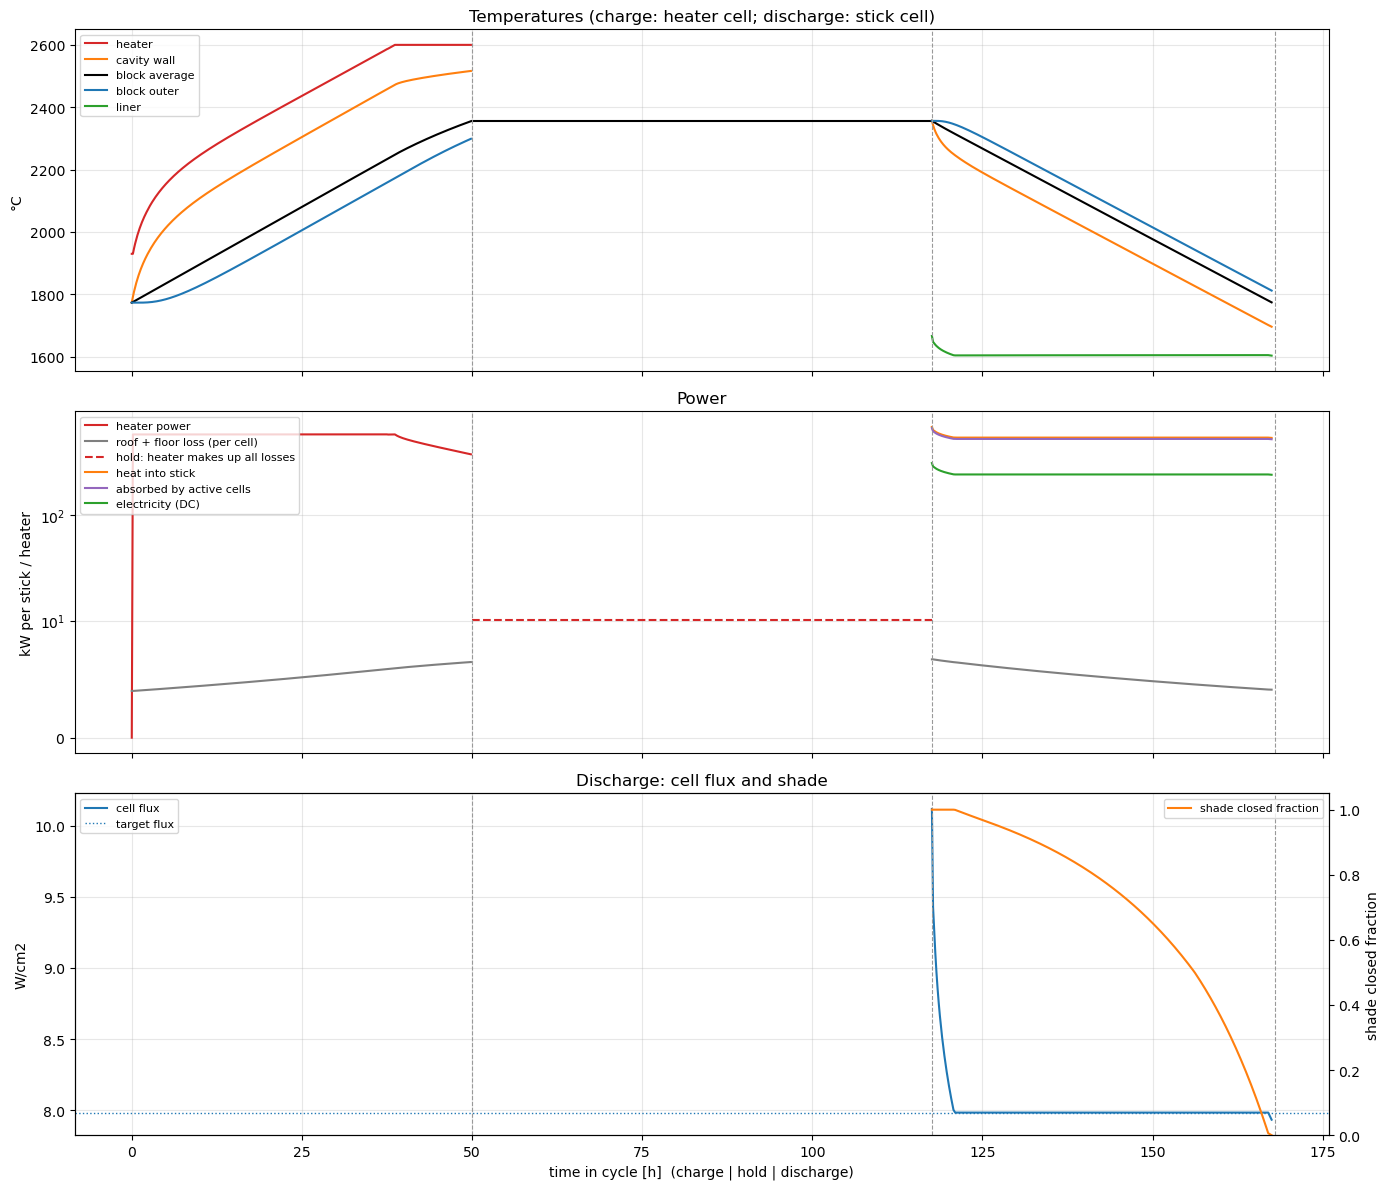

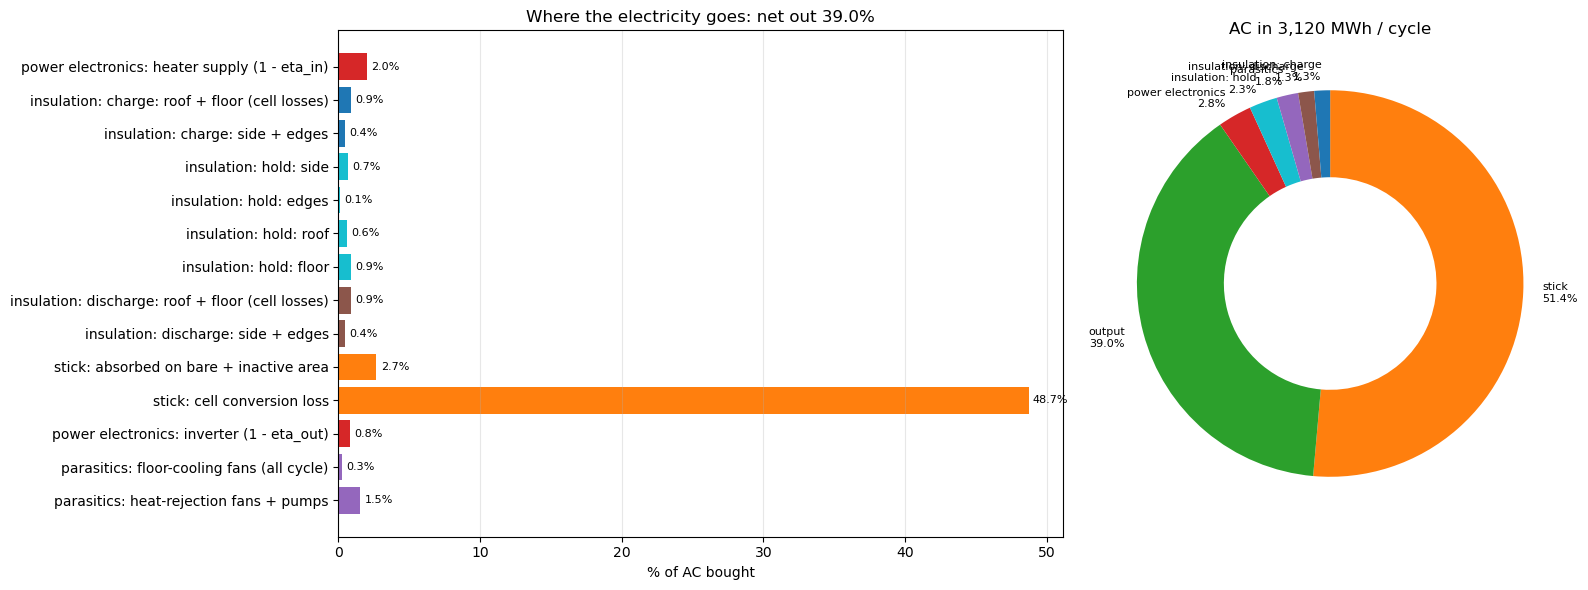

In [ ]:
# -- Full cycle of the top design at detailed settings --------------------------------
# best[CYCLE_RANK] from the results cell, charge -> hold -> discharge at O.DETAILED fidelity (0.33 m
# rings, 2^14 rays, full timestep), sized as the optimizer does: shade-open sizing of T_min and the
# block (T_max fixed), then the heater power + cavity search for charge_hr. Same outputs as the
# full-cycle cell of tinless system model.ipynb. Model: thermal/cycle.py. Takes ~10-20 min.
import thermal.cycle
importlib.reload(thermal.cycle)
from thermal.cycle import run_cycle, plot_layout, plot_timeseries, plot_losses

CYCLE_RANK = 0            # 0 = best design of the run
CYCLE_HR   = 168.0        # h: one-week cycle (charge + hold + discharge)

_top = best[CYCLE_RANK]
opt_det = O.merge(opt, {'fidelity': O.DETAILED})
_d = dict(_top['design'], T_min_guess_C=_top['T_min_C'])          # start the sizing at the run's T_min
cfg_top = O.design_cfg(base_cfg, _d, opt_det)
_sz = opt_det['sizing']
_t0 = time.perf_counter()
cy = run_cycle(cfg_top, opt=opt_det, cycle_hr=CYCLE_HR, charge_hr=opt_det['charge_hr'],
               resize_block=True, size_heater_cavity=True,
               resize_kw=dict(tol_T=_sz['tol_T'], tol_t=_sz['tol_t'], max_iter=_sz['max_iter'],
                              T_min_floor=opt_det['geometry']['T_min_floor_C'] + 273.15))
print(f"\n({(time.perf_counter() - _t0) / 60:.1f} min)  screening run: T_min {_top['T_min_C']:.0f} C, "
      f"RTE {_top['RTE']*100:.1f}%, {_top['N_ps']} sticks")

plot_layout(cy)
FIGS.keep('cycle_layout', 'Optimum to scale. Plan: sticks (blue) in square cavities turned 45 deg with liner and octagonal shade vanes (solid closed, dashed open), heaters (red) in round cavities, on a checkerboard in one graphite matrix; dashed circles = the annular cells the model analyses. Profile: vertical section through a stick and a heater.')
plt.show()
plot_timeseries(cy)
FIGS.keep('cycle_timeseries', 'One week cycle of the optimum (detailed settings, clean cells): temperatures, powers per stick / heater, and cell flux with the shade position during discharge.')
plt.show()
plot_losses(cy)
FIGS.keep('cycle_losses', 'Where the electricity bought in one cycle goes, as % of AC in (detailed settings, clean cells).')
plt.show()


In [ ]:
# -- Run report: report.docx (+ figures/, report_inputs.json) in LOG_DIR -----------------
# One Word document for coworkers (figures embedded): what was optimized and how,
# the variable ranges and the optimum, layout, efficiency, deposition and maintenance, the
# full-cycle ledger, the detailed check of the top designs, the best designs, every figure kept above
# (FIGS.keep), costs with the cost assumptions, all other inputs and the model (YAML) settings. Run
# after the cells above (needs python-docx);
# sections for cells that were not run are left out.
importlib.reload(thermal.report)
from thermal.report import write_report
_path = write_report(LOG_DIR, dict(
    opt=opt, opt_inputs=OPT_INPUTS, base_cfg=base_cfg, rows=rows, best=best, figs=FIGS,
    run=dict(RUN_DE=RUN_DE, WORKERS=WORKERS, POPSIZE=POPSIZE, MAXITER=MAXITER, SEED=SEED),
    de=globals().get('de') if RUN_DE else None, verified=globals().get('verified'), cycle=globals().get('cy'),
    yaml_path='tinless_model_input.yaml', notebook='tinless system optimizer.ipynb'))
print('Report:', os.path.abspath(_path))


Report: c:\Users\NateColgan\Documents\thermal modelling\opt_runs\20261120_161611_p150\report.docx


In [ ]:
# -- Model documentation: docs/tinless_model_documentation.docx ------------------------
# Word document describing the whole model for review: inputs, geometry, component physics (block,
# radiation, shades, liner, stick and cells, heater, deposition), tank and plant, transient simulation
# (with flowcharts), material properties, the cycle accounting with an example design, the optimizer,
# numerical settings and every item flagged for review. Tables are read from the code and YAML when
# it is built, so regenerate it after model changes.
# Example design: the best design of this run's LOG_DIR (or DOC_EXAMPLE_RUN), at detailed settings;
# reuses the full-cycle cell's result (cy) when that cell was run, otherwise runs it (~3-5 min).
import thermal.docs_base, thermal.docs
for _mod in (thermal.report, thermal.docs_base, thermal.docs):
    importlib.reload(_mod)
from thermal.docs import build_docs

DOC_PATH        = os.path.join('docs', 'tinless_model_documentation.docx')
DOC_EXAMPLE_RUN = None      # run folder for the example design; None = LOG_DIR if it has results, else latest

_ex = DOC_EXAMPLE_RUN or (LOG_DIR if any(r.get('feasible') for r in O.load_log(LOG_DIR)) else None)
_cy = globals().get('cy') if (DOC_EXAMPLE_RUN is None and globals().get('cy') is not None and best) else None
build_docs(DOC_PATH, base_cfg, opt, example_dir=_ex, cy=_cy, top=best[0] if _cy is not None else None)
print('Documentation:', os.path.abspath(DOC_PATH))


sections 2-4 ...
[docs secB] model probes 2 s
section 5 ...
section 6 ...
section 7 ...
written docs\tinless_model_documentation.docx (71 review items)
Documentation: c:\Users\NateColgan\Documents\thermal modelling\docs\tinless_model_documentation.docx


# Heater lead optimizer (separate from the system optimizer)

Sizes the current leads of one heater for **one system design** (a YAML, or a design row from an optimizer
run) and the **cost weights** of the inputs cell above (`OPT_INPUTS`, with its cost scenario). Each lead
runs from the element at the bottom face of the top Thermax up through it (`t_top`) to the terminal at
its top face, in up to three zones in series, hot -> cold (**graphite / tungsten / copper** and **graphite / tungsten / stainless steel**, `LEAD_ZONE_SETS`),
each a round bar with its own diameter and length (at least `min_zone_len`, 5 cm). Differential evolution
picks the diameters and lengths for the lowest **lifetime cost per lead**; any zone the optimum leaves at
the 5 cm minimum is then tried removed (graphite -> copper, tungsten -> copper, graphite only, ...) and the
cheapest set wins:

* **capex**: material (volume x $/m3) + joints + heat rejection on the peak rejected heat + heater-supply
  $/kW on the lead's Joule power, x (1 + soft_cost_frac)
* **energy** over the life at `elec_price` (as the system optimizer): Joule heat + storage heat drained
  (/ eta_in) + heat-rejection parasitics

1-D steady model along the lead, for charging (rated current; hot end at the heater max temperature) and
idle (no current; hot end at the block mean). It includes temperature-dependent k and electrical
resistivity, each joint kept below the colder material's T_max, and exchange with the insulation: gas conduction and radiation across the gap to the bore
wall, in series with radial conduction through the Thermax out to `r_far`, where the Thermax has its
undisturbed temperature: the exact steady 1-D profile with the Thermax k(T), from the block T_max at its
bottom face to `T_ins_cold` at the top. Each zone has a max service temperature. It runs twice: the last
(copper) zone **passive** (it has to stay under its T_max; the terminal at the top face is water-cooled),
and **water-cooled** along its length.

Model and assumptions: `thermal/heater_leads.py`. About 2-3 min per mode.

In [12]:
# -- Heater lead optimizer: inputs ---------------------------------------------------
import importlib
import thermal.heater, thermal.heater_leads
importlib.reload(thermal.heater); importlib.reload(thermal.heater_leads)
from thermal import heater_leads as HL
from thermal import optimize as O
from thermal.build import load_config

# lead model inputs: LEAD_ZONE_SETS and LEAD_INPUTS in the opt_leads cell (near the top)
LEAD_YAML = 'tinless_model_input.yaml'          # the system design (heater, block temperatures, t_top)
# cost weights: the optimizer inputs cell (scenario applied); override single values with O.merge, e.g.
# O.merge(OPT_INPUTS, {'economics': {'elec_price': 60.0}})
if 'OPT_INPUTS' not in globals():
    raise NameError("run the optimizer inputs cell (opt_inputs) first: it holds the cost weights")
LEAD_COST_INPUTS = OPT_INPUTS

# cases to run: (zone set, water-cooled last zone). All four: [(s, c) for s in LEAD_ZONE_SETS for c in (False, True)]
LEAD_CASES = [('copper', True)]
# also run every case with the joint after this zone opened while idle (hold + discharge; closed for
# charging): None = only the always-connected lead
LEAD_COMPARE_BREAK = 'graphite'

if 'LEAD_INPUTS' not in globals():
    raise NameError("run the opt_leads cell (heater lead inputs, after the optimizer inputs) first")
lead_cfg = load_config(LEAD_YAML)
lead_ctx = HL.lead_context(lead_cfg, LEAD_COST_INPUTS, LEAD_INPUTS)
_c, _i = lead_ctx['charge'], lead_ctx['idle']
print(f"Design from {lead_ctx['source']}: heater {lead_ctx['P']/1e3:,.0f} kW at {lead_ctx['V']:g} V -> "
      f"{lead_ctx['I']/1e3:,.2f} kA; lead length (t_top) {lead_ctx['L']:.2f} m; "
      f"{lead_ctx['li']['n_leads']} leads per heater"
      + (f"; {lead_ctx['N_heaters']} heaters" if lead_ctx['N_heaters'] else ''))
print(f"  Thermax {_c['T_ins_hot']-273.15:.0f} C (bottom, block T_max) -> {LEAD_INPUTS['T_ins_cold']-273.15:.0f} C (top); "
      f"lead hot end: charge {_c['hours']:.0f} h/cycle at {_c['T_hot']-273.15:.0f} C, "
      f"idle {_i['hours']:.0f} h/cycle at {_i['T_hot']-273.15:.0f} C")
print(f"  cost weights (scenario {lead_ctx['scenario'] or 'none'}): {lead_ctx['elec_price']:g} $/MWh, "
      f"{lead_ctx['cycles_life']:,.0f} cycles, eta_in {lead_ctx['eta_in']:g}, soft {lead_ctx['soft']:g}, "
      f"heat rejection {lead_ctx['hr_per_kWth']:g} $/kW_th + {lead_ctx['rej_kWe_per_kWth']:g} kW_e/kW_th")
_used = sorted({m for s, _ in LEAD_CASES for m in LEAD_ZONE_SETS[s]}, key=list(HL.MATERIALS).index)
print("  materials $/m3: " + ", ".join(f"{m} {lead_ctx['mats'][m]['cost_per_m3']:,.0f} "
                                       f"(T_max {lead_ctx['mats'][m]['T_max']-273.15:.0f} C)" for m in _used))

Design from YAML: heater 539 kW at 60 V -> 8.98 kA; lead length (t_top) 1.50 m; 2 leads per heater
  Thermax 2400 C (bottom, block T_max) -> 80 C (top); lead hot end: charge 50 h/cycle at 2600 C, idle 118 h/cycle at 2150 C
  cost weights (scenario none): 75 $/MWh, 1,564 cycles, eta_in 0.98, soft 0.3, heat rejection 125 $/kW_th + 0.03 kW_e/kW_th
  materials $/m3: graphite 18,500 (T_max 3000 C), tungsten 2,500,000 (T_max 2500 C), copper 110,000 (T_max 200 C)


In [10]:
# -- Heater lead optimizer: run (LEAD_CASES, connected / joint open when idle) ---------
import time
_t0 = time.perf_counter()
lead_base = HL.evaluate(lead_ctx, HL.baseline_lead(lead_ctx))
print(HL.describe(lead_ctx, lead_base, "Baseline: graphite, the element's cross-section through the insulation"))
print()
# each case (zone set, cooling), connected and (LEAD_COMPARE_BREAK) with the joint opened while idle: the
# full set, then without any zone an optimum leaves at min_zone_len
lead_ctxs = {'connected': lead_ctx}
if LEAD_COMPARE_BREAK:
    lead_ctxs[f"{LEAD_COMPARE_BREAK} joint open when idle"] = HL.lead_context(
        lead_cfg, LEAD_COST_INPUTS, O.merge(LEAD_INPUTS, {'idle_break_after': LEAD_COMPARE_BREAK}))
lead_best, lead_tried, lead_case_ctx = {}, {}, {}
for _var, _ctx in lead_ctxs.items():
    _cache = {}                        # per variant: the idle physics differ
    for _set, _cooled in LEAD_CASES:
        _k = f"{_set}, {'cooled' if _cooled else 'passive'}, {_var}"
        print(f"{_k}:")
        lead_best[_k], lead_tried[_k] = HL.optimize_with_skips(_ctx, _cooled, zones=LEAD_ZONE_SETS[_set], cache=_cache)
        lead_case_ctx[_k] = _ctx
print(f"({(time.perf_counter() - _t0) / 60:.1f} min)\n")
print("Zone sets tried, lifetime $ per lead:")
for _k, _tr in lead_tried.items():
    for _z, _r in sorted(_tr.items(), key=lambda kv: kv[1]['objective']):
        print(f"  {_k:<45s}{' / '.join(_z):<34s}" + (f"${_r['total']:>10,.0f}" if _r.get('ok') else '   no solution')
              + ('' if _r.get('feasible') else '  (T limit exceeded)') + ('   <- best' if _r is lead_best[_k] else ''))
print()
for _k, _r in lead_best.items():
    print(HL.describe(lead_case_ctx[_k], _r, f"Optimum, {_k}: {' / '.join(_r['lead']['mats'])}"))
    print()
print("Energy lost per lead (Joule + heat conducted out of the storage), % of heater power "
      f"{lead_ctx['P']/1e3:,.0f} kW; per cycle as % of the heater's charge energy:")
print(HL.loss_table({_k: (lead_case_ctx[_k], _r) for _k, _r in lead_best.items()}))
print()

# per heater: its two leads each connected or opened when not charging (the leads are independent, so a
# heater is the sum of its two leads): both connected, one opened, both opened
if LEAD_COMPARE_BREAK and lead_ctx['li']['n_leads'] == 2:
    _open = f"{LEAD_COMPARE_BREAK} joint open when idle"
    print(f"Per heater (2 leads), lifetime $ and energy lost (% of heater power {lead_ctx['P']/1e3:,.0f} kW):")
    print(f"  {'':<34s}{'lifetime $':>12s}{'capex $':>10s}{'energy $':>10s}{'charging %':>12s}{'hold %':>8s}"
          f"{'discharging %':>15s}{'kWh/cycle':>11s}")
    for _set, _cooled in LEAD_CASES:
        _base = f"{_set}, {'cooled' if _cooled else 'passive'}"
        _kc, _ko = f"{_base}, connected", f"{_base}, {_open}"
        if not (lead_best[_kc].get('ok') and lead_best[_ko].get('ok')):
            continue
        for _lab, _ks in (('both connected', (_kc, _kc)), ('one opened when not charging', (_kc, _ko)),
                          ('both opened when not charging', (_ko, _ko))):
            _rs = [lead_best[k] for k in _ks]
            _lo = [HL.losses(lead_case_ctx[k], lead_best[k]) for k in _ks]
            _ph = {ph: sum(l['rows'][ph]['lost_pct'] for l in _lo) for ph in ('charging', 'hold', 'discharging')}
            print(f"  {_lab:<34s}{sum(r['total'] for r in _rs):12,.0f}{sum(r['capex'] for r in _rs):10,.0f}"
                  f"{sum(r['energy_cost'] for r in _rs):10,.0f}{_ph['charging']:12.2f}{_ph['hold']:8.2f}"
                  f"{_ph['discharging']:15.2f}{sum(l['E_cycle_kWh'] for l in _lo):11,.0f}")
    print()
_win = min(lead_best, key=lambda k: lead_best[k]['objective'])
_r = lead_best[_win]
_N = lead_ctx['N_heaters']
print(f"Best: {_win}, ${_r['total']:,.0f} per lead, ${_r['total'] * lead_ctx['li']['n_leads']:,.0f} per heater"
      + (f", ${_r['total'] * lead_ctx['li']['n_leads'] * _N / 1e6:,.2f}M for {_N} heaters" if _N else '')
      + f" (lifetime: capex ${_r['capex']:,.0f} + energy ${_r['energy_cost']:,.0f} per lead)")

Baseline: graphite, the element's cross-section through the insulation (passive): $nan per lead, $nan per heater  ** NOT FEASIBLE **
  no steady solution (thermal runaway or no convergence)

copper, cooled, connected:
  graphite / tungsten / copper   cooled: $83,194 per lead
copper, cooled, graphite joint open when idle:
  graphite / tungsten / copper   cooled: $58,155 per lead
(11.1 min)

Zone sets tried, lifetime $ per lead:
  copper, cooled, connected                    graphite / tungsten / copper      $    83,194   <- best
  copper, cooled, graphite joint open when idlegraphite / tungsten / copper      $    58,155   <- best

Optimum, copper, cooled, connected: graphite / tungsten / copper (cooled last zone): $83,194 per lead, $166,388 per heater
  graphite   x  0.00- 1.10 m  D  497.0 mm (body)  J  0.05 A/mm2    369.6 kg  $   3,696  T max   2640 C (limit 3000)
  tungsten   x  1.10- 1.25 m  D  102.0 mm (body)  J  1.10 A/mm2     21.4 kg  $   2,775  T max   2451 C (limit 2500)
  coppe

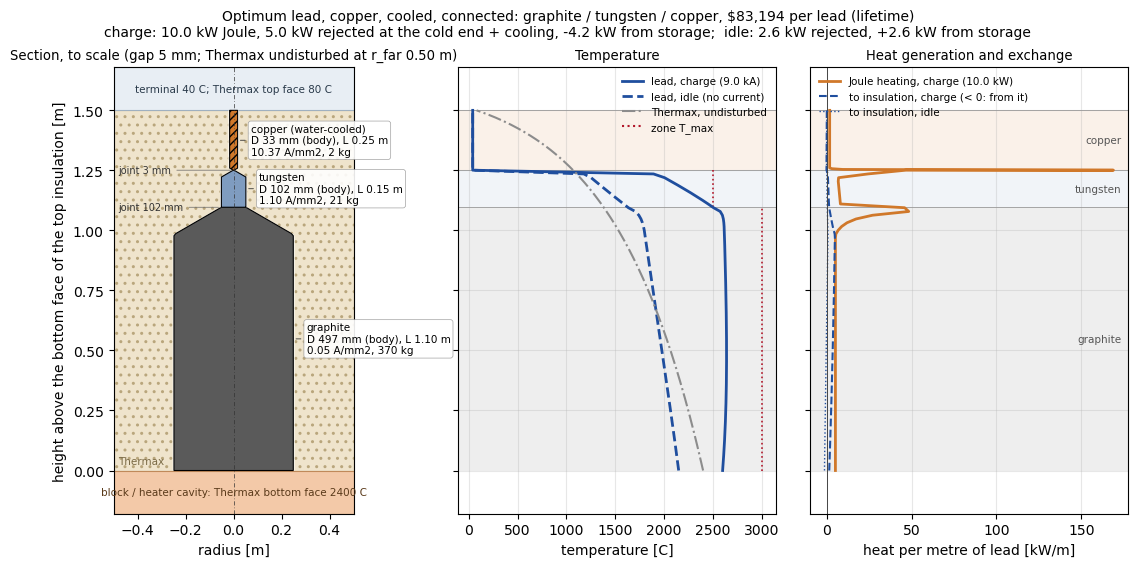

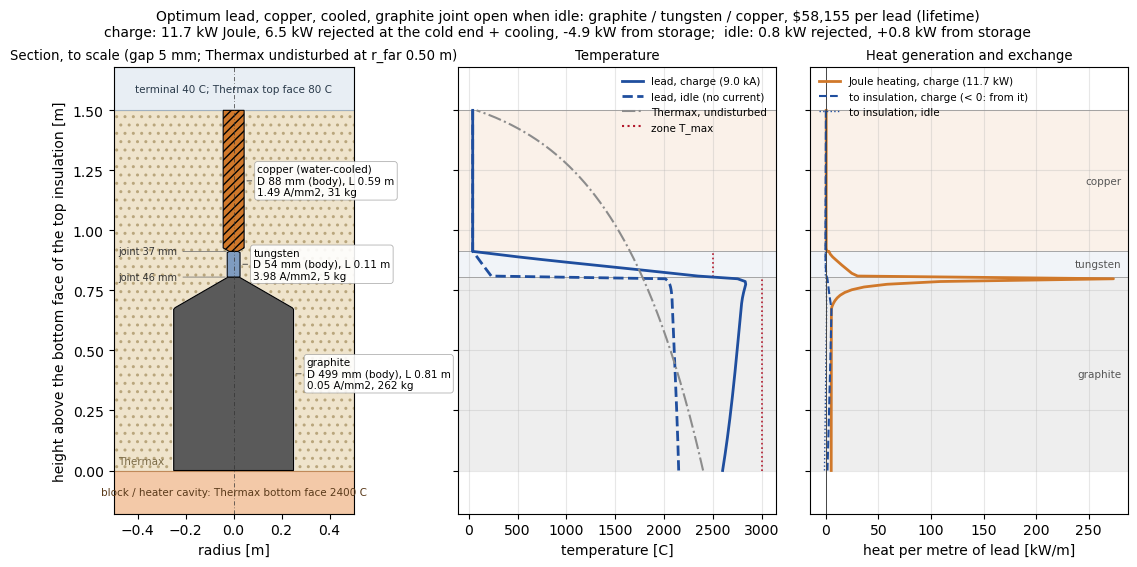

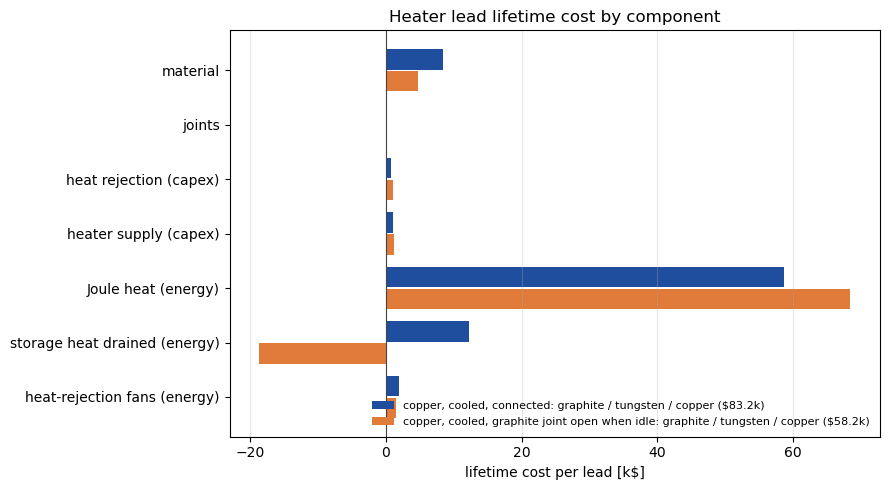

In [11]:
# -- Heater lead optimizer: temperatures and cost breakdown ----------------------------
# per mode: to-scale section of one lead (zones, diameters, Thermax around it) | temperature (charge, idle,
# undisturbed Thermax, zone limits) | heat per metre (Joule heating, exchange with the insulation)
for _k, _r in lead_best.items():
    if not _r.get('ok'):
        continue
    HL.plot_lead_section(lead_case_ctx.get(_k, lead_ctx), _r, title=f"Optimum lead, {_k}: {' / '.join(_r['lead']['mats'])}, "
                                             f"${_r['total']:,.0f} per lead (lifetime)")
    plt.show()

# lifetime cost per lead by component (storage heat < 0: Joule heat that flows into the block)
_parts = ['material', 'joints', 'heat_rejection', 'supply', 'joule', 'storage_heat', 'rejection_parasitic']
_labels = ['material', 'joints', 'heat rejection (capex)', 'heater supply (capex)', 'Joule heat (energy)',
           'storage heat drained (energy)', 'heat-rejection fans (energy)']
_fig, _ax = plt.subplots(figsize=(9, 5))
_y = np.arange(len(_parts))
_cols = ['#1f4e9e', '#e07b39', '#2a9d8f', '#8e5ba8', '#c9a227', '#6b6b6b']
_ok = {k: r for k, r in lead_best.items() if r.get('ok')}
_h = 0.8 / max(len(_ok), 1)
for _j, (_k, _r) in enumerate(_ok.items()):
    _v = [{**_r['capex_parts'], **_r['energy_parts']}[p] / 1e3 for p in _parts]
    _ax.barh(_y + (_j - (len(_ok) - 1) / 2) * _h, _v, height=_h * 0.95, color=_cols[_j % len(_cols)],
             label=f"{_k}: {' / '.join(_r['lead']['mats'])} (${_r['total']/1e3:,.1f}k)")
_ax.set_yticks(_y); _ax.set_yticklabels(_labels); _ax.invert_yaxis()
_ax.axvline(0, color='#444444', lw=0.8)
_ax.set_xlabel('lifetime cost per lead [k$]'); _ax.grid(axis='x', alpha=0.3)
_ax.legend(frameon=False, loc='lower right', fontsize=8)
_ax.set_title('Heater lead lifetime cost by component')
plt.tight_layout(); plt.show()

lead table: 48 lead optimizations on 20 workers ...
lead table: done in 11.1 min; saved opt_runs/_lead_tables\lead_table_b6e17d8c54ce.json
Lead table b6e17d8c54ce (scenario none, 75 $/MWh): lifetime $ per kA per lead; kWh lost per cycle per kA
  I = 4 kA      T_max   1800 C   T_max   2033 C   T_max   2267 C   T_max   2500 C   
  t_top  0.5 m       4,390  33.8      4,631  35.8      4,887  37.8      5,180  39.9    
  t_top  1.0 m       4,810  35.8      5,073  38.1      5,368  40.3      5,700  42.7    
  t_top  1.5 m       5,186  37.6      5,479  40.1      5,795  42.4      6,111  44.8    
  t_top  2.0 m       5,545  39.3      5,867  42.0      6,187  44.3      6,534  46.8    
  t_top  2.5 m       5,903  41.1      6,238  43.7      6,592  46.2      6,969  48.7    
  t_top  3.0 m       6,262  42.8      6,621  45.5      6,998  48.1      7,357  50.7    
  I = 10 kA      T_max   1800 C   T_max   2033 C   T_max   2267 C   T_max   2500 C   
  t_top  0.5 m       4,589  35.5      4,902  38.3      5,

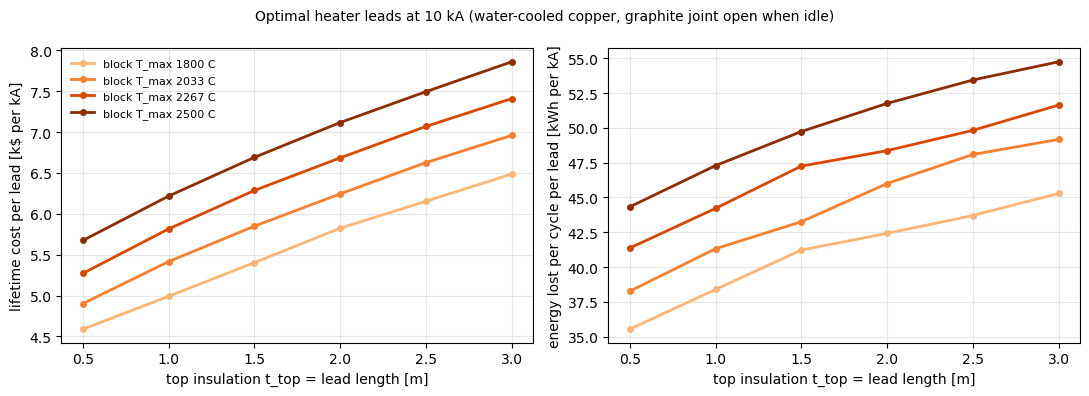

In [13]:
# -- Heater lead table used by the system optimizer (built in the opt_leads cell) -----
# Optimal leads (water-cooled copper; graphite joint open when idle) on t_top x block T_max at two
# currents, built with the cost weights and lead inputs above. The system optimizer will interpolate it
# (HL.LeadTable: linear in t_top and T_max, per ampere linear in current) instead of optimizing leads for
# every design. Cached in opt_runs/_lead_tables under a hash of all its inputs: rebuilt only when the
# costs, scenario or lead inputs change. ~10-15 min to build (process pool).
# the table the system optimizer uses (opt_leads cell); built here if that cell ran with USE_LEAD_TABLE = False
if 'lead_table' not in globals():
    lead_table = HL.build_lead_table(lead_cfg, LEAD_COST_INPUTS, LEAD_INPUTS, LEAD_TABLE)
print(lead_table.summary())

_g = lead_table.data['grid']
_rows = {(r['I_kA'], r['t_top'], r['T_max_C']): r for r in lead_table.data['rows']}
_I = _g['I_kA'][-1]
_fig, _axs = plt.subplots(1, 2, figsize=(11, 4))
_cmap = plt.get_cmap('Oranges')
for _j, _T in enumerate(_g['T_max_C']):
    _c = _cmap(0.35 + 0.6 * _j / max(len(_g['T_max_C']) - 1, 1))
    _ok = [t for t in _g['t_top'] if _rows[(_I, t, _T)].get('ok')]
    _axs[0].plot(_ok, [_rows[(_I, t, _T)]['total'] / _I / 1e3 for t in _ok], 'o-', color=_c, lw=2, ms=4,
                 label=f"block T_max {_T:.0f} C")
    _axs[1].plot(_ok, [_rows[(_I, t, _T)]['E_cycle_kWh'] / _I for t in _ok], 'o-', color=_c, lw=2, ms=4)
_axs[0].set_ylabel('lifetime cost per lead [k$ per kA]')
_axs[1].set_ylabel('energy lost per cycle per lead [kWh per kA]')
for _ax in _axs:
    _ax.set_xlabel('top insulation t_top = lead length [m]')
    _ax.grid(alpha=0.3)
_axs[0].legend(frameon=False, fontsize=8)
_fig.suptitle(f"Optimal heater leads at {_I:g} kA (water-cooled copper, graphite joint open when idle)", fontsize=10)
plt.tight_layout(); plt.show()